**Setup and install**

In [2]:
!pip install ucimlrepo -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

**Acquire the data (Stage 1: Acquire)**

In [3]:
from ucimlrepo import fetch_ucirepo

data = fetch_ucirepo(id=350)          # UCI: Default of Credit Card Clients
X = data.data.features.copy()
y = data.data.targets.copy()

# Rename columns by position to meaningful names
X.columns = (["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE"]
             + ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
             + [f"BILL_AMT{i}" for i in range(1, 7)]
             + [f"PAY_AMT{i}" for i in range(1, 7)])
y.columns = ["default"]

df = pd.concat([X, y], axis=1)
print("Shape:", df.shape)
df.head()

Shape: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


**Data understanding (Stage 2: Parse)**

In [4]:
print(df.info())
print("\nMissing values per column:\n", df.isnull().sum().sum(), "total")
print("Duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:\n", df["default"].value_counts())
print("Default rate: {:.2%}".format(df["default"].mean()))
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_1      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   3

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


**Check categorical codes and data-quality problems**

In [5]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(col, df[col].value_counts().sort_index().to_dict())

print("\nPAY_1 values:", sorted(df["PAY_1"].unique()))
print("Negative BILL_AMT1 rows:", (df["BILL_AMT1"] < 0).sum())

SEX {1: 11888, 2: 18112}
EDUCATION {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE {0: 54, 1: 13659, 2: 15964, 3: 323}

PAY_1 values: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Negative BILL_AMT1 rows: 590


**Cleaning (Stage 3: Filter)**

In [6]:
df_clean = df.copy()

# 1. Missing values (this dataset has none, but handle generically)
if df_clean.isnull().sum().sum() > 0:
    num_cols = df_clean.select_dtypes("number").columns
    df_clean[num_cols] = df_clean[num_cols].fillna(df_clean[num_cols].median())

# 2. Duplicates
before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df_clean)} duplicate rows")

# 3. Fix undocumented category codes
df_clean["EDUCATION"] = df_clean["EDUCATION"].replace({0: 4, 5: 4, 6: 4})  # -> 'others'
df_clean["MARRIAGE"]  = df_clean["MARRIAGE"].replace({0: 3})               # -> 'others'

# 4. Outliers: IQR winsorizing (cap, don't delete) on continuous amount columns
cont_cols = (["LIMIT_BAL", "AGE"]
             + [f"BILL_AMT{i}" for i in range(1, 7)]
             + [f"PAY_AMT{i}" for i in range(1, 7)])

print("\nOutlier counts (IQR rule) before capping:")
for c in cont_cols:
    q1, q3 = df_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_clean[c] < lo) | (df_clean[c] > hi)).sum()
    print(f"  {c:10s}: {n_out}")

df_capped = df_clean.copy()
for c in cont_cols:
    q1, q3 = df_clean[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    df_capped[c] = df_clean[c].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

print("\nClean shape:", df_clean.shape)

Removed 35 duplicate rows

Outlier counts (IQR rule) before capping:
  LIMIT_BAL : 167
  AGE       : 272
  BILL_AMT1 : 2386
  BILL_AMT2 : 2390
  BILL_AMT3 : 2469
  BILL_AMT4 : 2616
  BILL_AMT5 : 2724
  BILL_AMT6 : 2688
  PAY_AMT1  : 2742
  PAY_AMT2  : 2723
  PAY_AMT3  : 2596
  PAY_AMT4  : 2993
  PAY_AMT5  : 2944
  PAY_AMT6  : 2960

Clean shape: (29965, 24)


**Feature engineering and transformation**

In [7]:
df_model = df_capped.copy()

# Useful engineered features (helps feature-analysis marks)
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_cols  = [f"PAY_AMT{i}" for i in range(1, 7)]
delay_cols = [f"PAY_{i}" for i in range(1, 7)]

df_model["AVG_BILL"]       = df_model[bill_cols].mean(axis=1)
df_model["AVG_PAYMENT"]    = df_model[pay_cols].mean(axis=1)
df_model["UTILIZATION"]    = df_model["AVG_BILL"] / df_model["LIMIT_BAL"]
df_model["AVG_DELAY"]      = df_model[delay_cols].mean(axis=1)

# Encode categoricals (one-hot). PAY_x are ordinal delay codes -> keep numeric.
df_model["SEX"] = df_model["SEX"].map({1: "Male", 2: "Female"})
df_model["EDUCATION"] = df_model["EDUCATION"].map(
    {1: "GradSchool", 2: "University", 3: "HighSchool", 4: "Others"})
df_model["MARRIAGE"] = df_model["MARRIAGE"].map(
    {1: "Married", 2: "Single", 3: "Others"})
df_model = pd.get_dummies(df_model, columns=["SEX", "EDUCATION", "MARRIAGE"],
                          drop_first=True, dtype=int)

print("Model-ready shape:", df_model.shape)
df_model.head()

Model-ready shape: (29965, 31)


,LIMIT_BAL,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default,AVG_BILL,AVG_PAYMENT,UTILIZATION,AVG_DELAY,SEX_Male,EDUCATION_HighSchool,EDUCATION_Others,EDUCATION_University,MARRIAGE_Others,MARRIAGE_Single
0,20000,24.0,2,2,-1,-1,-2,-2,3913.0,3102.0,689,0.0,0,0,0,689,0,0,0.0,0.0,1,1284.000000,114.833333,0.064200,-0.333333,0,0,0,1,0,0
1,120000,26.0,-1,2,0,0,0,2,2682.0,1725.0,2682,3272.0,3455,3261,0,1000,1000,1000,0.0,2000.0,1,2846.166667,833.333333,0.023718,0.500000,0,0,0,1,0,1
2,90000,34.0,0,0,0,0,0,0,29239.0,14027.0,13559,14331.0,14948,15549,1518,1500,1000,1000,1000.0,5000.0,0,16942.166667,1836.333333,0.188246,0.000000,0,0,0,1,0,1
3,50000,37.0,0,0,0,0,0,0,46990.0,48233.0,49291,28314.0,28959,29547,2000,2019,1200,1100,1069.0,1000.0,0,38555.666667,1398.000000,0.771113,0.000000,0,0,0,1,0,0
4,50000,57.0,-1,0,-1,0,0,0,8617.0,5670.0,35835,20940.0,19146,19131,2000,11225,10000,9000,689.0,679.0,0,18223.166667,5598.833333,0.364463,-0.333333,1,0,0,1,0,0


**Train, validation and test split, then scaling**

In [8]:
X_all = df_model.drop(columns="default")
y_all = df_model["default"]

# 70% train / 15% val / 15% test, stratified to keep the default ratio
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

# Standardize: fit on TRAIN only (prevents data leakage)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print("Train:", X_train_s.shape, "| Val:", X_val_s.shape, "| Test:", X_test_s.shape)
print("Default rate -> train {:.3f}, val {:.3f}, test {:.3f}".format(
      y_train.mean(), y_val.mean(), y_test.mean()))

Train: (20975, 30) | Val: (4495, 30) | Test: (4495, 30)
Default rate -> train 0.221, val 0.221, test 0.221


**Save processed data (for GitHub)**

In [9]:
import os
os.makedirs("data", exist_ok=True)
df.to_csv("data/credit_default_raw.csv", index=False)
df_clean.to_csv("data/credit_default_clean.csv", index=False)
df_model.to_csv("data/credit_default_model_ready.csv", index=False)
print("Saved to /content/data/")

Saved to /content/data/


**Helpers and labelled copy**

In [10]:
import os
from scipy import stats
import plotly.express as px

os.makedirs("figures", exist_ok=True)

def save_fig(name):
    """Save every figure to /figures for the report and GitHub, then show it."""
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

# Human-readable copy of the cleaned (uncapped) data, used only for plotting
lab = df_clean.copy()
lab["SEX"] = lab["SEX"].map({1: "Male", 2: "Female"})
lab["EDUCATION"] = lab["EDUCATION"].map(
    {1: "Grad School", 2: "University", 3: "High School", 4: "Others"})
lab["MARRIAGE"] = lab["MARRIAGE"].map({1: "Married", 2: "Single", 3: "Others"})
lab["Status"] = lab["default"].map({0: "No default", 1: "Default"})

overall = lab["default"].mean()
palette = {"No default": "#4C72B0", "Default": "#DD5555"}

**Mine stage (statistical tests)**

In [11]:
# Descriptive statistics with skewness and kurtosis (CO4: univariate summaries)
cont4 = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]
print(df_clean[cont4].agg(["mean", "median", "std", "skew", "kurt"]).T.round(2))

# Chi-square: is each categorical variable related to default?
print("\nChi-square tests vs default")
for col in ["SEX", "EDUCATION", "MARRIAGE", "PAY_1"]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df_clean[col], df_clean["default"]))
    print(f"  {col:10s} chi2 = {chi2:10.1f}   p = {p:.2e}")

# Mann-Whitney U: do continuous variables differ between defaulters and non-defaulters?
print("\nMann-Whitney U tests vs default")
for col in cont4:
    a = df_clean.loc[df_clean.default == 1, col]
    b = df_clean.loc[df_clean.default == 0, col]
    u, p = stats.mannwhitneyu(a, b)
    print(f"  {col:10s} median(default) = {a.median():>10.0f}  median(no default) = {b.median():>10.0f}   p = {p:.2e}")

                mean    median        std   skew    kurt
LIMIT_BAL  167442.01  140000.0  129760.14   0.99    0.54
AGE            35.49      34.0       9.22   0.73    0.04
BILL_AMT1   51283.01   22438.0   73658.13   2.66    9.80
PAY_AMT1     5670.10    2102.0   16571.85  14.66  414.85

Chi-square tests vs default
  SEX        chi2 =       47.1   p = 6.64e-12
  EDUCATION  chi2 =      160.5   p = 1.46e-34
  MARRIAGE   chi2 =       27.5   p = 1.07e-06
  PAY_1      chi2 =     5363.5   p = 0.00e+00

Mann-Whitney U tests vs default
  LIMIT_BAL  median(default) =      90000  median(no default) =     150000   p = 6.15e-190
  AGE        median(default) =         34  median(no default) =         34   p = 4.04e-01
  BILL_AMT1  median(default) =      20210  median(no default) =      23242   p = 9.38e-06
  PAY_AMT1   median(default) =       1641  median(no default) =       2474   p = 1.14e-170


**Visual 1: Target balance and default rate by category (univariate/bivariate, discrete)**

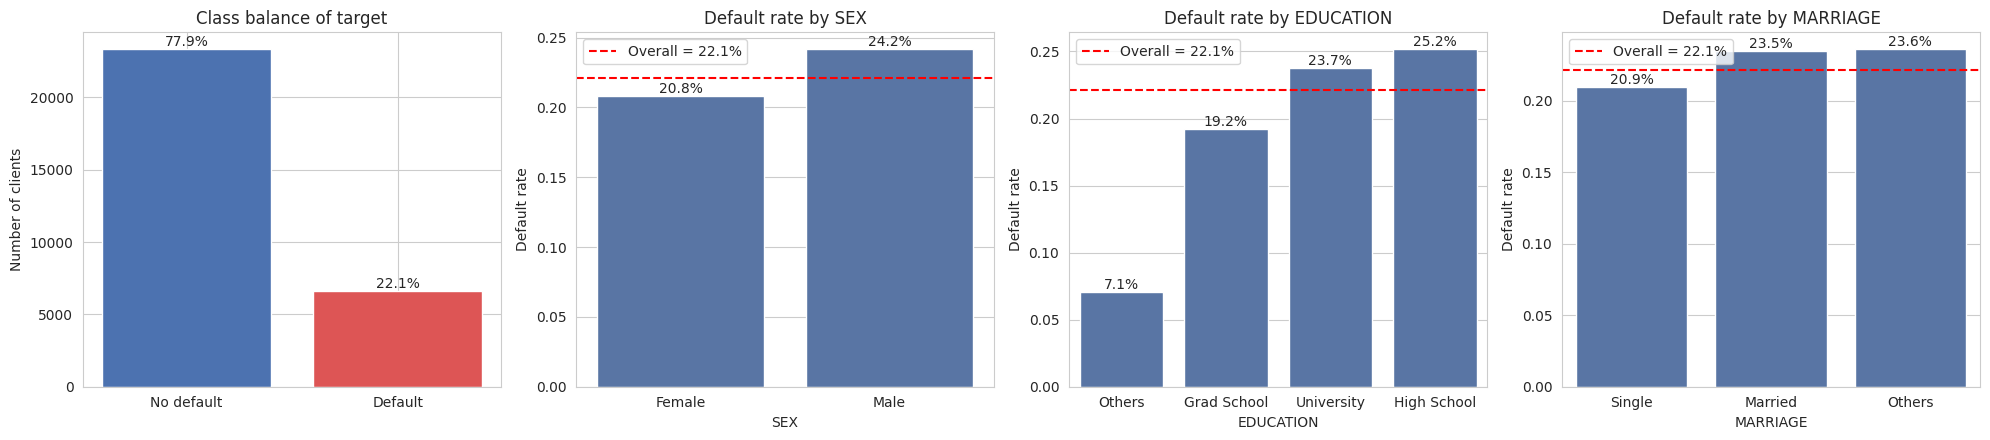

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))

counts = lab["Status"].value_counts()
ax[0].bar(counts.index, counts.values, color=[palette[i] for i in counts.index])
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v/len(lab):.1%}", ha="center", va="bottom")
ax[0].set_title("Class balance of target"); ax[0].set_ylabel("Number of clients")

for a, col in zip(ax[1:], ["SEX", "EDUCATION", "MARRIAGE"]):
    rate = lab.groupby(col)["default"].mean().sort_values()
    sns.barplot(x=rate.index, y=rate.values, ax=a, color="#4C72B0")
    a.axhline(overall, color="red", ls="--", label=f"Overall = {overall:.1%}")
    for i, v in enumerate(rate.values):
        a.text(i, v, f"{v:.1%}", ha="center", va="bottom")
    a.set_title(f"Default rate by {col}"); a.set_ylabel("Default rate"); a.legend()
save_fig("v1_target_and_categorical")

**Visual 2: PAY_1 repayment status, discrete distribution with default rate**

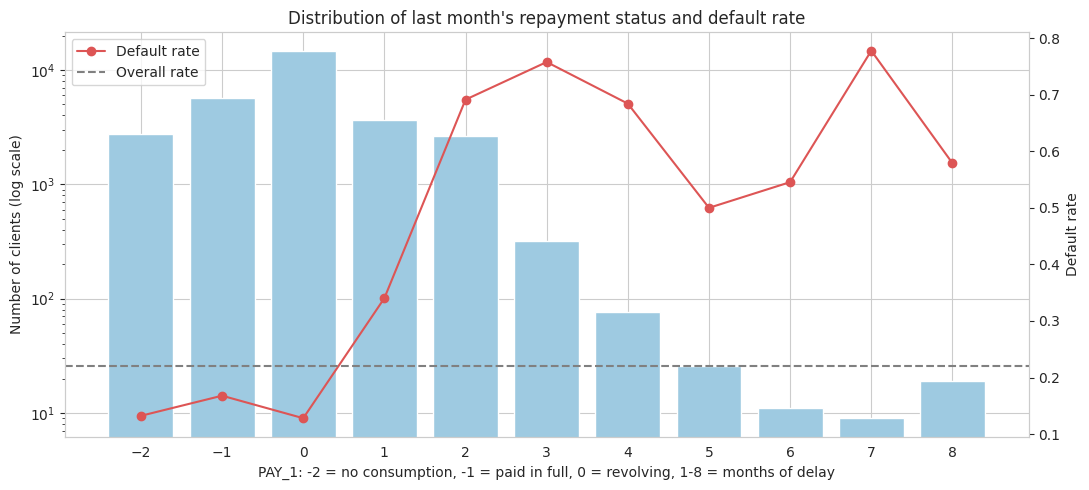

In [13]:
tab = lab.groupby("PAY_1")["default"].agg(["count", "mean"])

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(tab.index, tab["count"], color="#9ecae1")
ax1.set_yscale("log"); ax1.set_xticks(tab.index)
ax1.set_xlabel("PAY_1: -2 = no consumption, -1 = paid in full, 0 = revolving, 1-8 = months of delay")
ax1.set_ylabel("Number of clients (log scale)")

ax2 = ax1.twinx()
ax2.plot(tab.index, tab["mean"], "o-", color="#DD5555", label="Default rate")
ax2.axhline(overall, color="grey", ls="--", label="Overall rate")
ax2.set_ylabel("Default rate"); ax2.grid(False); ax2.legend(loc="upper left")
ax1.set_title("Distribution of last month's repayment status and default rate")
save_fig("v2_pay1_discrete")

**Visual 3: Discrete probability distribution (observed vs Binomial)**

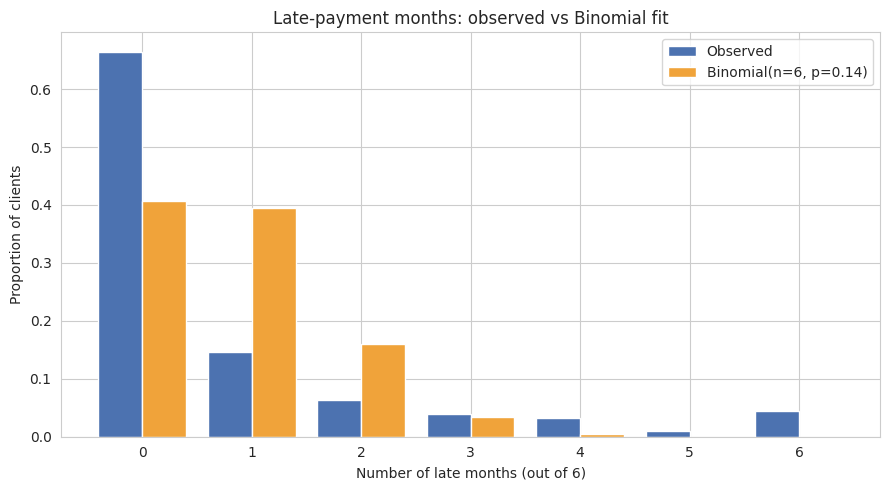

Observed mean = 0.83, variance = 2.42
Binomial variance = 0.72


In [14]:
delay_cols = [f"PAY_{i}" for i in range(1, 7)]
late = (df_clean[delay_cols] > 0).sum(axis=1)         # months late out of 6

obs = late.value_counts(normalize=True).sort_index().reindex(range(7), fill_value=0)
p_hat = late.mean() / 6
binom = stats.binom.pmf(range(7), 6, p_hat)

x, w = np.arange(7), 0.4
plt.figure(figsize=(9, 5))
plt.bar(x - w/2, obs.values, w, label="Observed", color="#4C72B0")
plt.bar(x + w/2, binom, w, label=f"Binomial(n=6, p={p_hat:.2f})", color="#F0A33A")
plt.xlabel("Number of late months (out of 6)"); plt.ylabel("Proportion of clients")
plt.title("Late-payment months: observed vs Binomial fit"); plt.legend()
save_fig("v3_binomial_fit")

print(f"Observed mean = {late.mean():.2f}, variance = {late.var():.2f}")
print(f"Binomial variance = {6*p_hat*(1-p_hat):.2f}")

**Visual 4: Continuous distributions (histogram + KDE)**

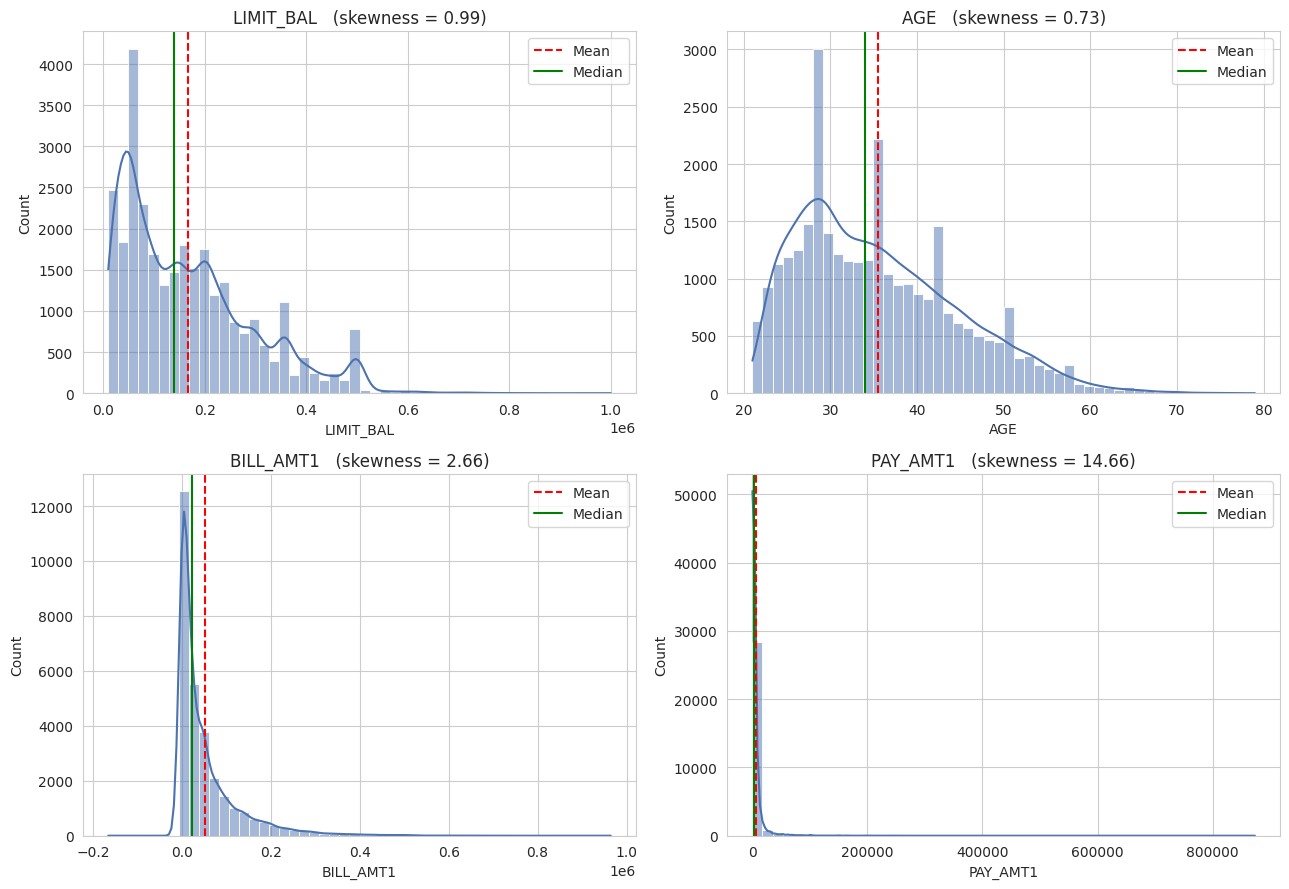

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for a, c in zip(axes.ravel(), cont4):
    sns.histplot(df_clean[c], kde=True, bins=50, ax=a, color="#4C72B0")
    a.axvline(df_clean[c].mean(), color="red", ls="--", label="Mean")
    a.axvline(df_clean[c].median(), color="green", ls="-", label="Median")
    a.set_title(f"{c}   (skewness = {df_clean[c].skew():.2f})")
    a.set_xlabel(c); a.legend()
save_fig("v4_continuous_distributions")

**Visual 5: Q-Q plot before and after log transform (Refine stage)**

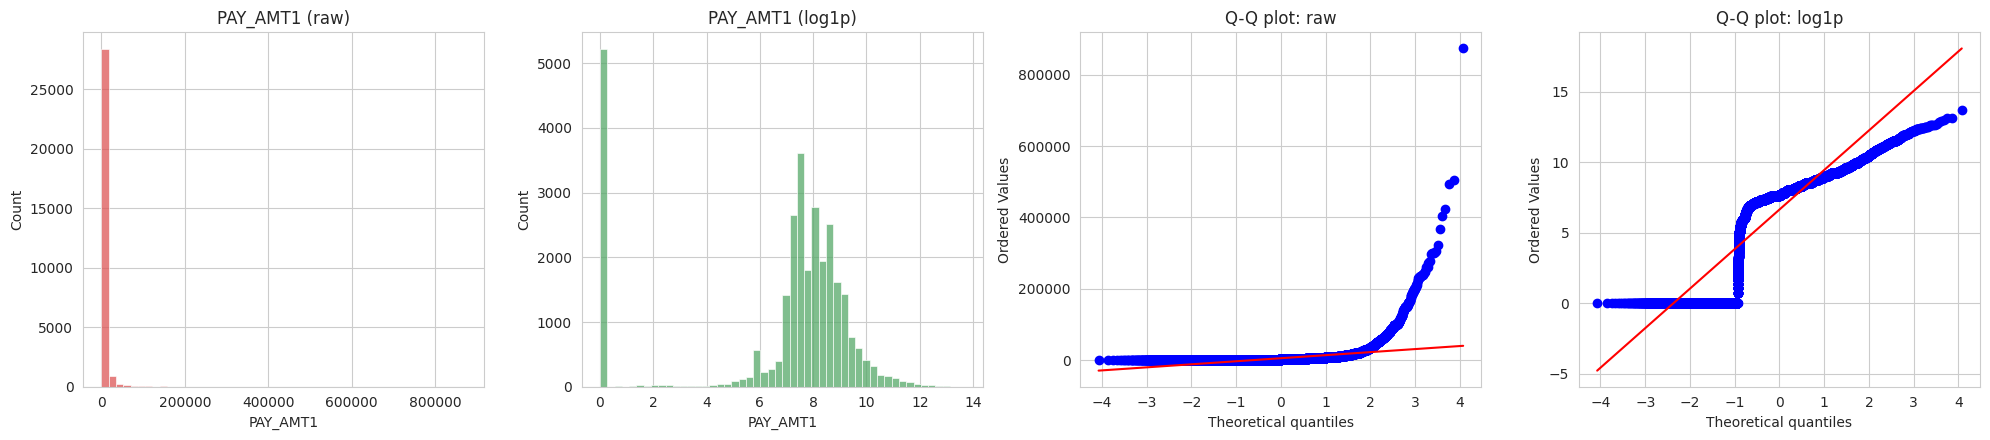

Skewness raw = 14.66  ->  log1p = -1.30


In [16]:
raw = df_clean["PAY_AMT1"]
logged = np.log1p(raw)

fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
sns.histplot(raw, bins=50, ax=ax[0], color="#DD5555");   ax[0].set_title("PAY_AMT1 (raw)")
sns.histplot(logged, bins=50, ax=ax[1], color="#55A868"); ax[1].set_title("PAY_AMT1 (log1p)")
stats.probplot(raw, dist="norm", plot=ax[2]);    ax[2].set_title("Q-Q plot: raw")
stats.probplot(logged, dist="norm", plot=ax[3]); ax[3].set_title("Q-Q plot: log1p")
save_fig("v5_log_transform_qq")
print(f"Skewness raw = {raw.skew():.2f}  ->  log1p = {logged.skew():.2f}")

**Visual 6: Outliers before and after capping (Filter + Refine)**

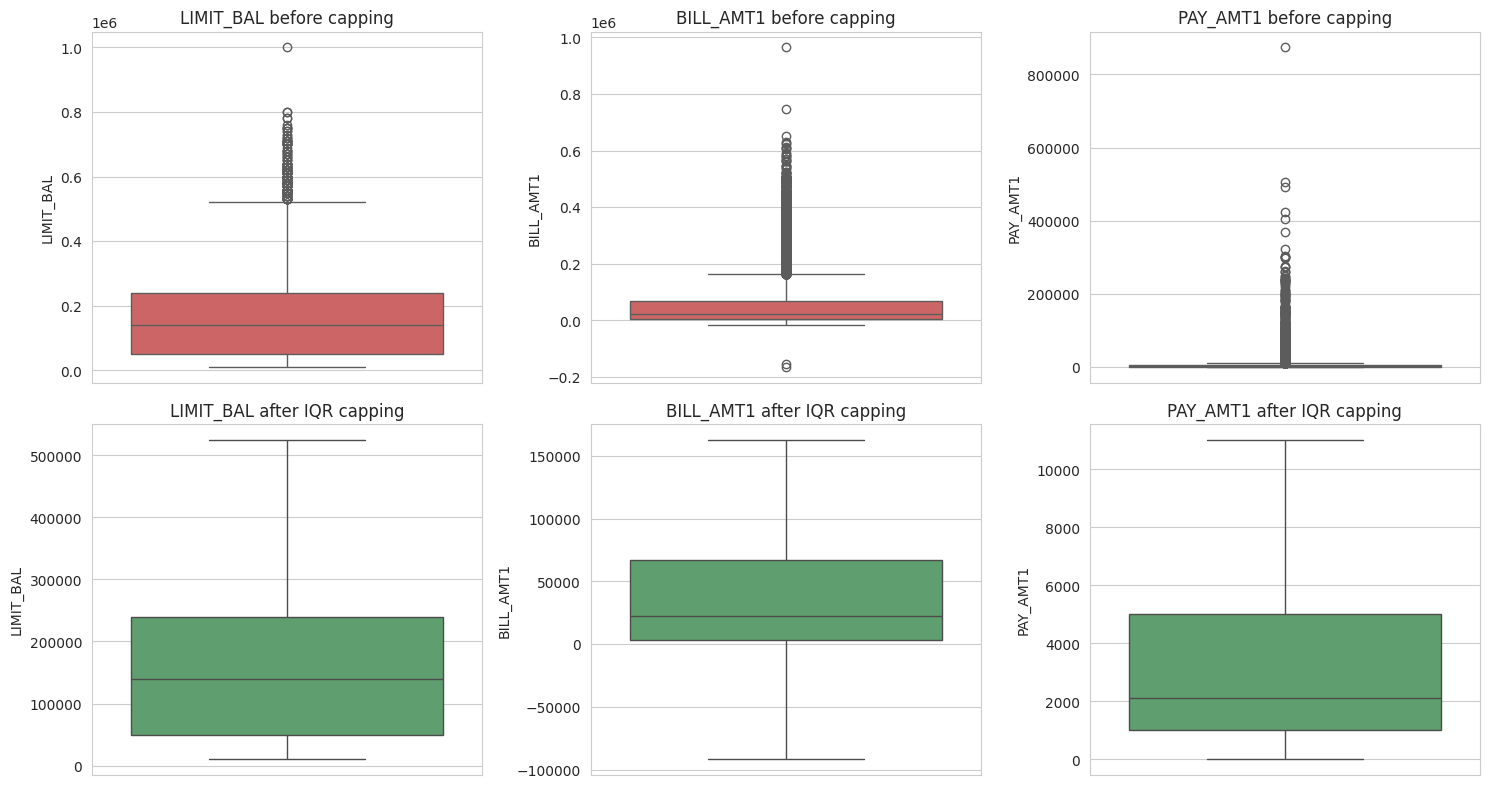

In [17]:
cols = ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, c in enumerate(cols):
    sns.boxplot(y=df_clean[c], ax=axes[0, j], color="#DD5555")
    axes[0, j].set_title(f"{c} before capping")
    sns.boxplot(y=df_capped[c], ax=axes[1, j], color="#55A868")
    axes[1, j].set_title(f"{c} after IQR capping")
save_fig("v6_outliers_before_after")

**Visual 7: Bivariate analysis (continuous vs target, age groups, scatter)**

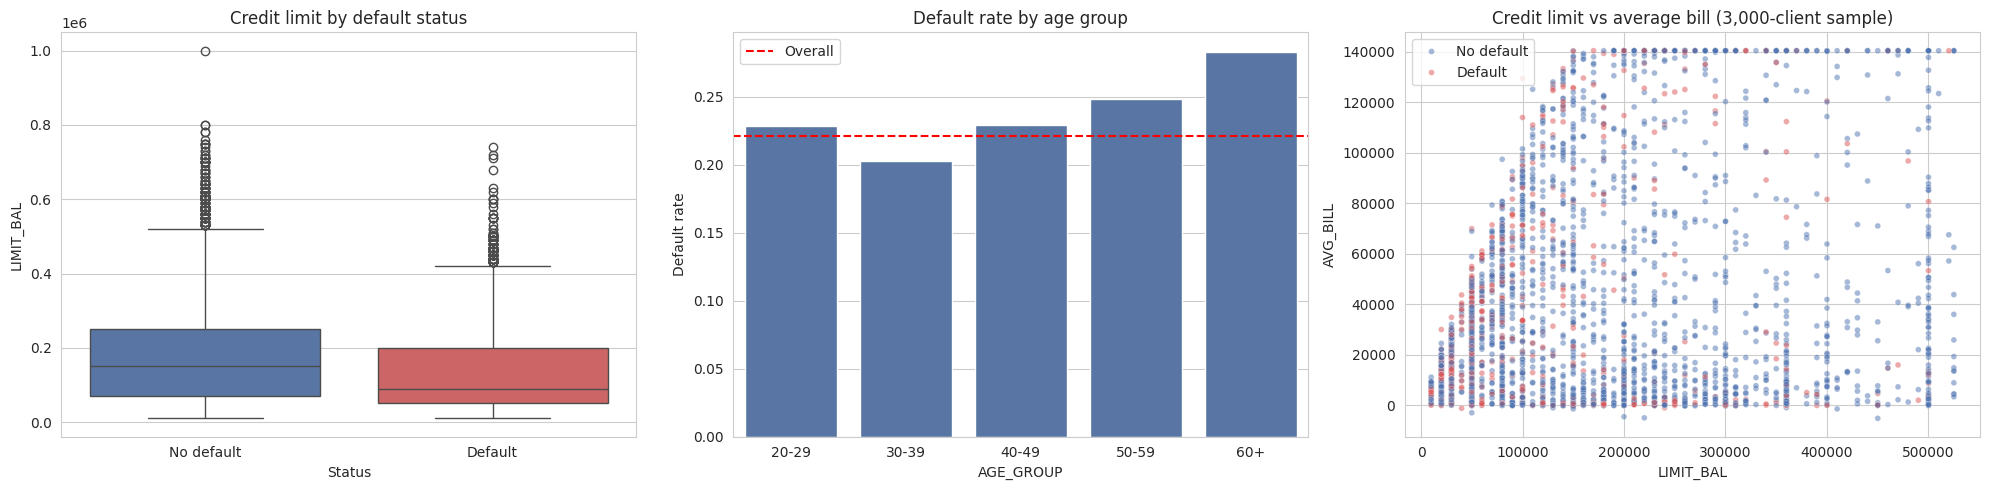

In [18]:
lab["AGE_GROUP"] = pd.cut(lab["AGE"], [20, 30, 40, 50, 60, 80], right=False,
                          labels=["20-29", "30-39", "40-49", "50-59", "60+"])
samp = df_model.sample(3000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(1, 3, figsize=(20, 5))

sns.boxplot(data=lab, x="Status", y="LIMIT_BAL", hue="Status", palette=palette,
            legend=False, order=["No default", "Default"], ax=ax[0])
ax[0].set_title("Credit limit by default status")

rate = lab.groupby("AGE_GROUP", observed=True)["default"].mean()
sns.barplot(x=rate.index, y=rate.values, ax=ax[1], color="#4C72B0")
ax[1].axhline(overall, color="red", ls="--", label="Overall")
ax[1].set_title("Default rate by age group"); ax[1].set_ylabel("Default rate"); ax[1].legend()

sns.scatterplot(data=samp, x="LIMIT_BAL", y="AVG_BILL",
                hue=samp["default"].map({0: "No default", 1: "Default"}),
                palette=palette, alpha=0.5, s=18, ax=ax[2])
ax[2].set_title("Credit limit vs average bill (3,000-client sample)")
ax[2].legend(title="")
save_fig("v7_bivariate")

**Visual 8: Correlation heatmap (multivariate)**

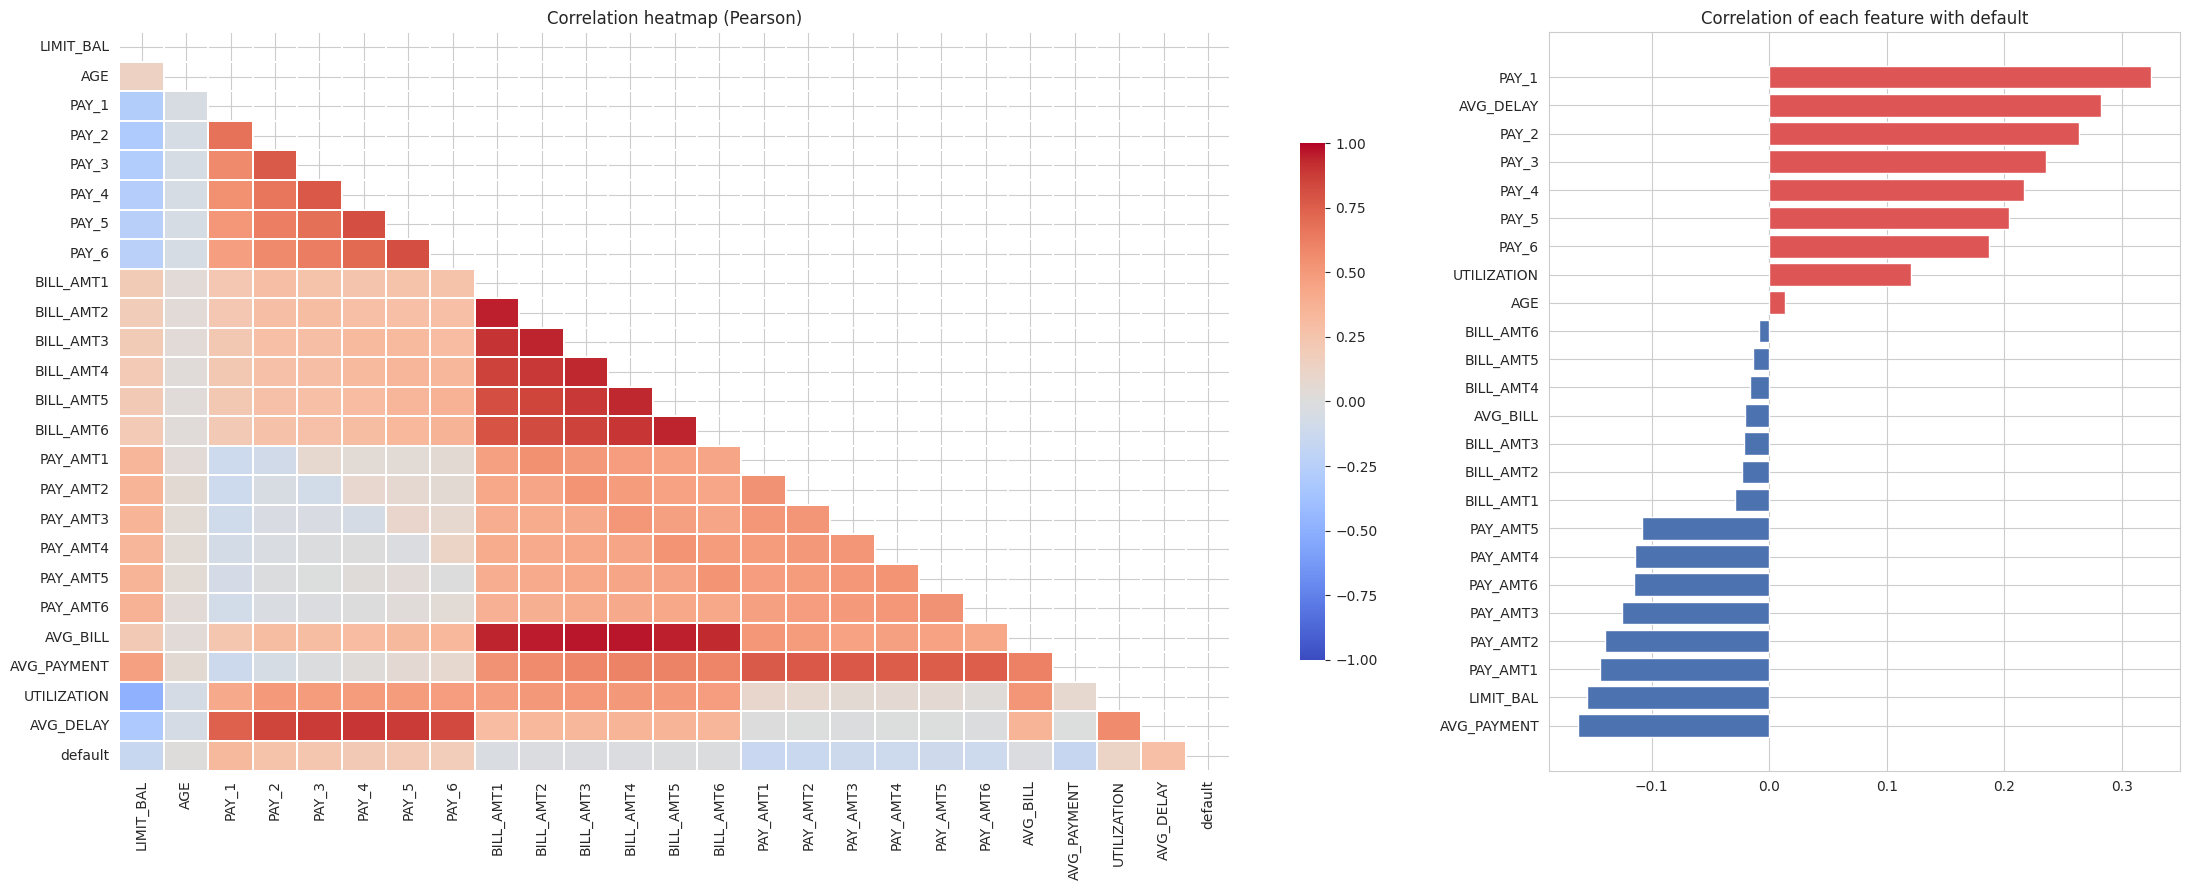

In [19]:
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_cols = [f"PAY_AMT{i}" for i in range(1, 7)]
num_cols = (["LIMIT_BAL", "AGE"] + delay_cols + bill_cols + pay_cols
            + ["AVG_BILL", "AVG_PAYMENT", "UTILIZATION", "AVG_DELAY", "default"])

corr = df_model[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(1, 2, figsize=(22, 9), gridspec_kw={"width_ratios": [2.2, 1]})
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.3, cbar_kws={"shrink": 0.7}, ax=ax[0])
ax[0].set_title("Correlation heatmap (Pearson)")

tgt = corr["default"].drop("default").sort_values()
ax[1].barh(tgt.index, tgt.values, color=np.where(tgt > 0, "#DD5555", "#4C72B0"))
ax[1].set_title("Correlation of each feature with default")
save_fig("v8_correlation")

**Visual 9: Pairplot (multivariate)**

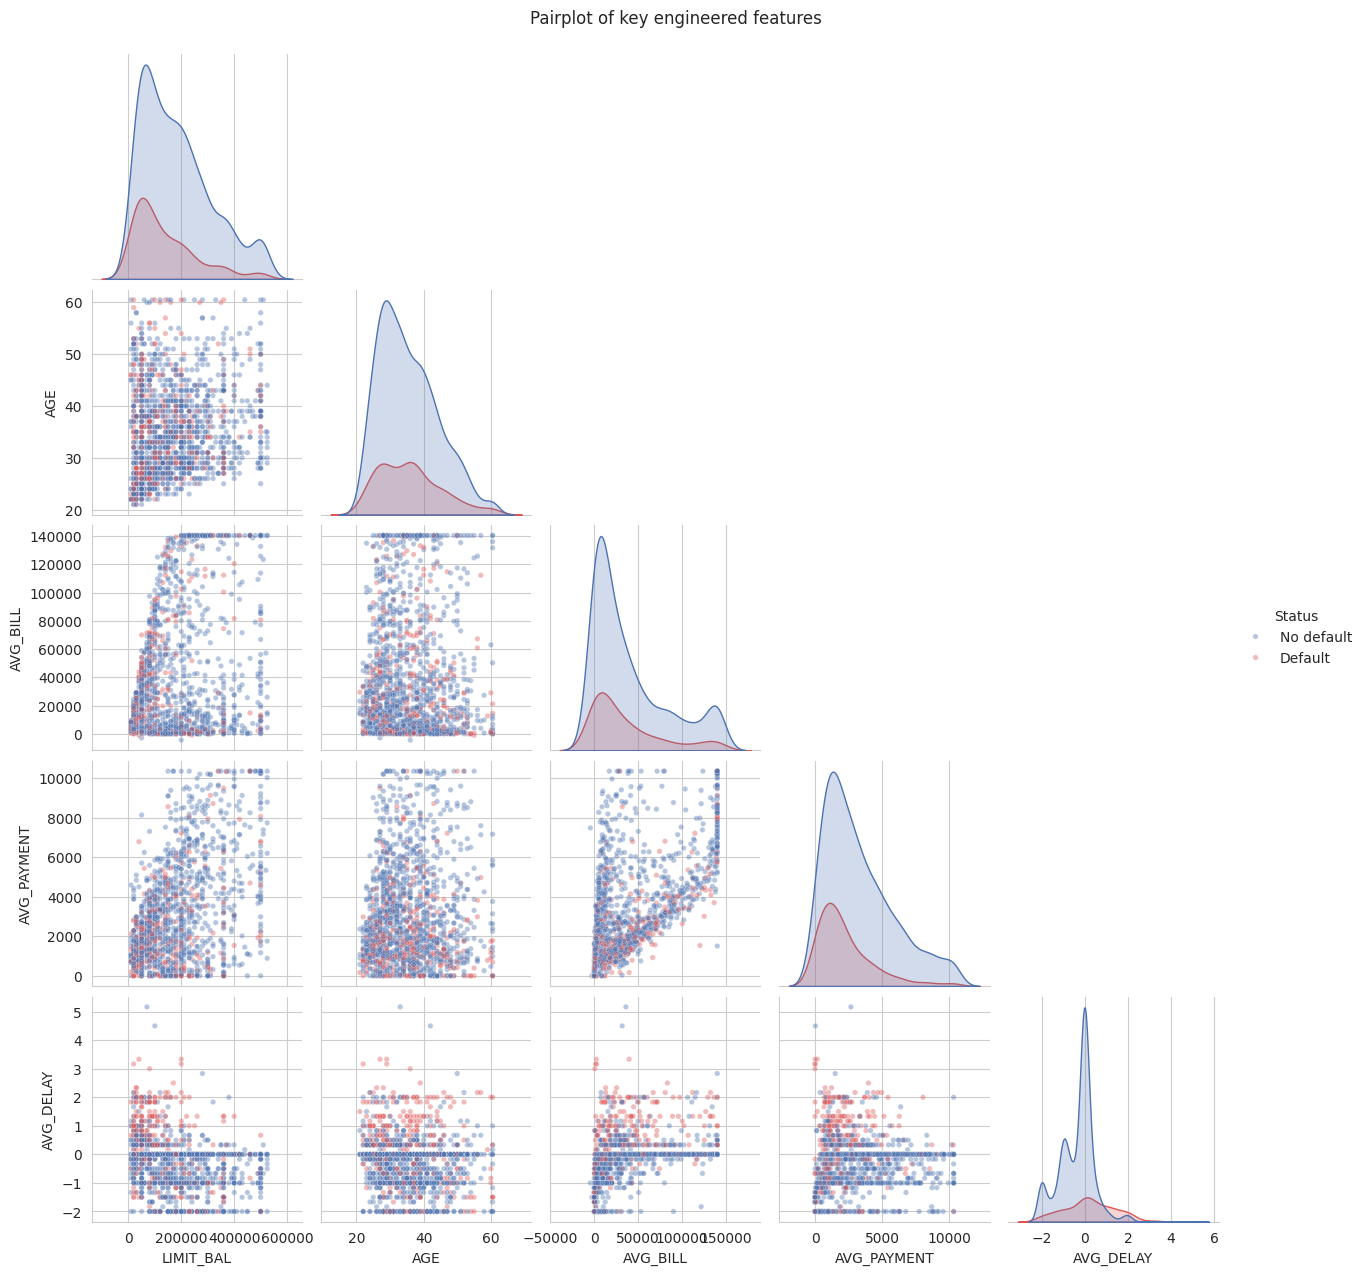

In [20]:
key = ["LIMIT_BAL", "AGE", "AVG_BILL", "AVG_PAYMENT", "AVG_DELAY"]
ps = df_model[key + ["default"]].sample(1500, random_state=RANDOM_STATE).copy()
ps["Status"] = ps["default"].map({0: "No default", 1: "Default"})

g = sns.pairplot(ps.drop(columns="default"), hue="Status", palette=palette,
                 corner=True, plot_kws={"alpha": 0.4, "s": 15})
g.fig.suptitle("Pairplot of key engineered features", y=1.02)
g.savefig("figures/v9_pairplot.png", dpi=200, bbox_inches="tight")
plt.show()

**Visual 10: Interactive visuals (Interact stage)**

In [23]:
# 10a: Interactive scatter with hover details
s = lab.sample(4000, random_state=RANDOM_STATE).copy()
s["AVG_BILL"] = s[bill_cols].mean(axis=1)
fig = px.scatter(s, x="LIMIT_BAL", y="AVG_BILL", color="Status",
                 color_discrete_map=palette, opacity=0.6,
                 hover_data=["AGE", "EDUCATION", "PAY_1"],
                 title="Interactive: credit limit vs average bill")
fig.write_html("figures/v10a_interactive_scatter.html")
fig.show()

# 10b: Interactive heatmap, default rate by education x repayment status
piv = (lab.assign(PAY_1c=lab["PAY_1"].clip(upper=3))
          .pivot_table(index="EDUCATION", columns="PAY_1c",
                       values="default", aggfunc="mean"))
fig2 = px.imshow(piv, text_auto=".0%", color_continuous_scale="Reds", aspect="auto",
                 labels=dict(x="PAY_1 (3 = 3+ months late)", y="Education",
                             color="Default rate"),
                 title="Interactive: default rate by education and repayment status")
fig2.write_html("figures/v10b_interactive_heatmap.html")
fig2.show()

**Download all figures for the report**

In [22]:
!zip -rq figures.zip figures
from google.colab import files
files.download("figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Setup**

In [24]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_auc_score
import itertools, time, json

keras.utils.set_random_seed(RANDOM_STATE)

feature_names = X_all.columns.tolist()
n_features = X_train_s.shape[1]
ytr, yva, yte = y_train.values, y_val.values, y_test.values

# Class imbalance (~22% defaults): weight the minority class higher
w = compute_class_weight("balanced", classes=np.array([0, 1]), y=ytr)
class_weight = {0: w[0], 1: w[1]}
print("Features:", n_features)
print("Class weights:", {k: round(v, 2) for k, v in class_weight.items()})

Features: 30
Class weights: {0: np.float64(0.64), 1: np.float64(2.26)}


**Feature analysis and feature importance (before modeling)**

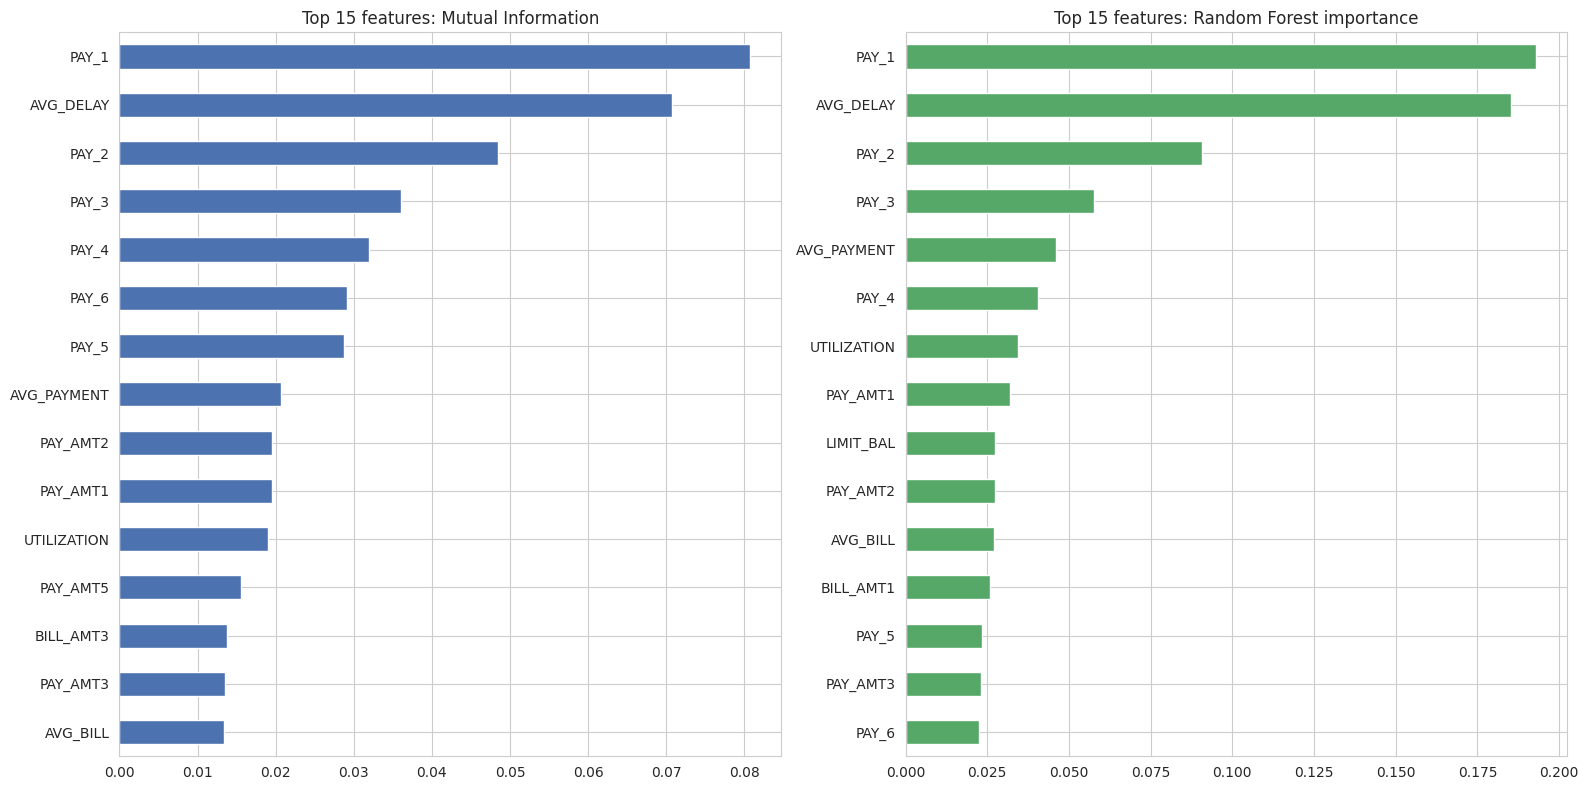

Baseline Logistic Regression  val AUC = 0.7217
Baseline Random Forest        val AUC = 0.7733


In [25]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# 1. Mutual information (captures non-linear dependence on the target)
mi = pd.Series(mutual_info_classif(X_train_s, ytr, random_state=RANDOM_STATE),
               index=feature_names).sort_values(ascending=False)

# 2. Random Forest importance (also serves as a baseline model)
rf = RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced",
                            n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train, ytr)
rf_imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
mi.head(15)[::-1].plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_title("Top 15 features: Mutual Information")
rf_imp.head(15)[::-1].plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title("Top 15 features: Random Forest importance")
save_fig("v11_feature_importance_pre_model")

# Baselines for comparison with the MLP (validation AUC)
lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train_s, ytr)
print(f"Baseline Logistic Regression  val AUC = {roc_auc_score(yva, lr.predict_proba(X_val_s)[:,1]):.4f}")
print(f"Baseline Random Forest        val AUC = {roc_auc_score(yva, rf.predict_proba(X_val)[:,1]):.4f}")

**Model builder**

In [26]:
def build_mlp(units=(64, 32), dropout=0.3, lr=1e-3, l2=1e-4):
    model = keras.Sequential([keras.Input(shape=(n_features,))])
    for u in units:
        model.add(layers.Dense(u, activation="relu",
                               kernel_regularizer=regularizers.l2(l2)))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

build_mlp().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

**Basic hyperparameter tuning (grid search on validation AUC)**

In [27]:
grid = {
    "units":   [(32, 16), (64, 32), (128, 64)],
    "dropout": [0.2, 0.4],
    "lr":      [1e-3, 3e-3],
}

results = []
for units, dropout, lr_ in itertools.product(grid["units"], grid["dropout"], grid["lr"]):
    keras.utils.set_random_seed(RANDOM_STATE)
    m = build_mlp(units, dropout, lr_)
    es = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5,
                                       restore_best_weights=True)
    t0 = time.time()
    h = m.fit(X_train_s, ytr, validation_data=(X_val_s, yva), epochs=40,
              batch_size=256, class_weight=class_weight, callbacks=[es], verbose=0)
    best = max(h.history["val_auc"])
    results.append({"units": str(units), "dropout": dropout, "lr": lr_,
                    "best_val_auc": round(best, 4), "epochs": len(h.history["val_auc"]),
                    "time_s": round(time.time() - t0, 1)})
    print(f"{str(units):10s} dropout={dropout} lr={lr_:<6} -> val AUC {best:.4f}")

tune_df = pd.DataFrame(results).sort_values("best_val_auc", ascending=False).reset_index(drop=True)
tune_df.to_csv("data/hyperparameter_tuning_results.csv", index=False)
tune_df

(32, 16)   dropout=0.2 lr=0.001  -> val AUC 0.7756
(32, 16)   dropout=0.2 lr=0.003  -> val AUC 0.7751
(32, 16)   dropout=0.4 lr=0.001  -> val AUC 0.7720
(32, 16)   dropout=0.4 lr=0.003  -> val AUC 0.7761
(64, 32)   dropout=0.2 lr=0.001  -> val AUC 0.7789
(64, 32)   dropout=0.2 lr=0.003  -> val AUC 0.7776
(64, 32)   dropout=0.4 lr=0.001  -> val AUC 0.7768
(64, 32)   dropout=0.4 lr=0.003  -> val AUC 0.7771
(128, 64)  dropout=0.2 lr=0.001  -> val AUC 0.7772
(128, 64)  dropout=0.2 lr=0.003  -> val AUC 0.7742
(128, 64)  dropout=0.4 lr=0.001  -> val AUC 0.7773
(128, 64)  dropout=0.4 lr=0.003  -> val AUC 0.7760


,units,dropout,lr,best_val_auc,epochs,time_s
0,"(64, 32)",0.2,0.001,0.7789,40,53.1
1,"(64, 32)",0.2,0.003,0.7776,19,21.1
2,"(128, 64)",0.4,0.001,0.7773,27,17.6
3,"(128, 64)",0.2,0.001,0.7772,21,14.4
4,"(64, 32)",0.4,0.003,0.7771,23,12.7
5,"(64, 32)",0.4,0.001,0.7768,40,20.9
6,"(32, 16)",0.4,0.003,0.7761,32,15.2
7,"(128, 64)",0.4,0.003,0.7760,15,11.3
8,"(32, 16)",0.2,0.001,0.7756,40,41.6
9,"(32, 16)",0.2,0.003,0.7751,19,15.3


**Train the final model with the best hyperparameters**

In [28]:
best_cfg = tune_df.iloc[0]
best_units = eval(best_cfg["units"])
print("Best configuration:", dict(best_cfg))

keras.utils.set_random_seed(RANDOM_STATE)
model = build_mlp(best_units, best_cfg["dropout"], best_cfg["lr"])

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=10,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
]

history = model.fit(X_train_s, ytr, validation_data=(X_val_s, yva),
                    epochs=100, batch_size=256, class_weight=class_weight,
                    callbacks=callbacks, verbose=2)

print(f"\nEpochs trained: {len(history.history['loss'])}")
print(f"Best val AUC:   {max(history.history['val_auc']):.4f}")

# Save for Step 5 and for GitHub
os.makedirs("model", exist_ok=True)
model.save("model/mlp_credit_default.keras")
pd.DataFrame(history.history).to_csv("data/training_history.csv", index=False)

Best configuration: {'units': '(64, 32)', 'dropout': np.float64(0.2), 'lr': np.float64(0.001), 'best_val_auc': np.float64(0.7789), 'epochs': np.int64(40), 'time_s': np.float64(53.1)}
Epoch 1/100
82/82 - 2s - 27ms/step - accuracy: 0.6107 - auc: 0.6925 - loss: 0.6420 - val_accuracy: 0.6578 - val_auc: 0.7410 - val_loss: 0.6329 - learning_rate: 0.0010
Epoch 2/100
82/82 - 1s - 9ms/step - accuracy: 0.6926 - auc: 0.7343 - loss: 0.6140 - val_accuracy: 0.7206 - val_auc: 0.7486 - val_loss: 0.6173 - learning_rate: 0.0010
Epoch 3/100
82/82 - 1s - 8ms/step - accuracy: 0.7199 - auc: 0.7466 - loss: 0.6043 - val_accuracy: 0.7326 - val_auc: 0.7523 - val_loss: 0.6081 - learning_rate: 0.0010
Epoch 4/100
82/82 - 1s - 9ms/step - accuracy: 0.7329 - auc: 0.7550 - loss: 0.5956 - val_accuracy: 0.7471 - val_auc: 0.7536 - val_loss: 0.5937 - learning_rate: 0.0010
Epoch 5/100
82/82 - 1s - 8ms/step - accuracy: 0.7375 - auc: 0.7573 - loss: 0.5943 - val_accuracy: 0.7422 - val_auc: 0.7577 - val_loss: 0.5968 - learning

**Feature importance for the trained MLP (permutation importance)**

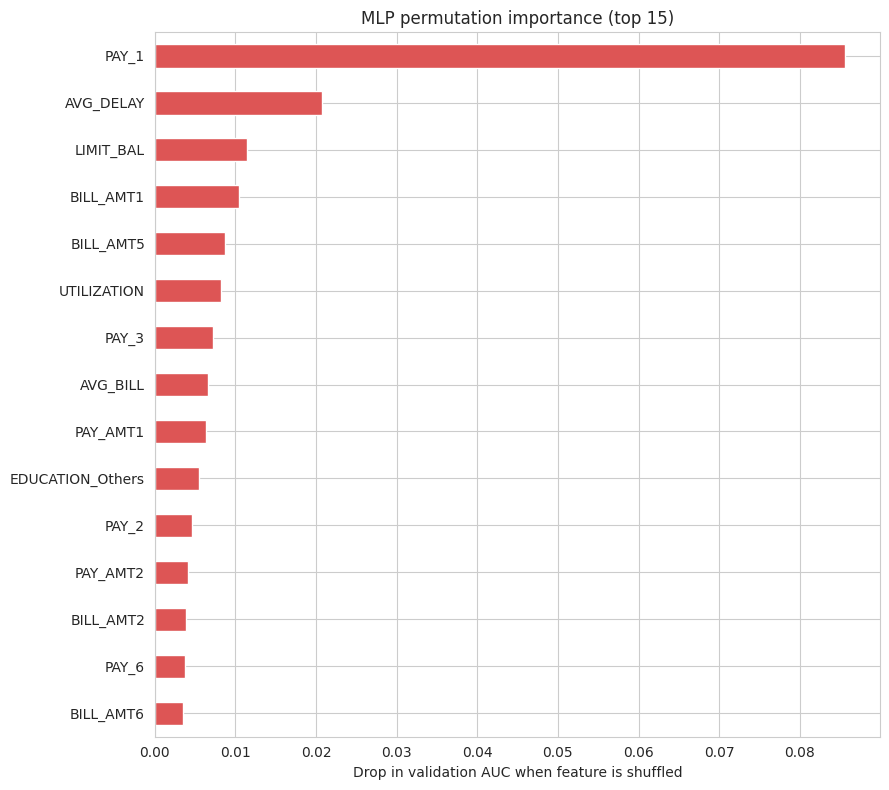

PAY_1               0.0857
AVG_DELAY           0.0208
LIMIT_BAL           0.0115
BILL_AMT1           0.0105
BILL_AMT5           0.0087
UTILIZATION         0.0082
PAY_3               0.0072
AVG_BILL            0.0066
PAY_AMT1            0.0063
EDUCATION_Others    0.0055
dtype: float64


In [29]:
# Shuffle one feature at a time on the VALIDATION set; the bigger the AUC drop, the more the model relies on it
base_auc = roc_auc_score(yva, model.predict(X_val_s, verbose=0).ravel())
rng = np.random.default_rng(RANDOM_STATE)

drops = {}
for j, name in enumerate(feature_names):
    scores = []
    for _ in range(5):
        Xp = X_val_s.copy()
        Xp[:, j] = rng.permutation(Xp[:, j])
        scores.append(roc_auc_score(yva, model.predict(Xp, verbose=0).ravel()))
    drops[name] = base_auc - np.mean(scores)

perm = pd.Series(drops).sort_values(ascending=False)

plt.figure(figsize=(9, 8))
perm.head(15)[::-1].plot.barh(color="#DD5555")
plt.xlabel("Drop in validation AUC when feature is shuffled")
plt.title("MLP permutation importance (top 15)")
save_fig("v12_mlp_permutation_importance")
print(perm.head(10).round(4))

**Summary table for the report (Section 7)**

In [30]:
summary = {
    "Architecture": f"Input({n_features}) -> " + " -> ".join(
        f"Dense({u}, ReLU)+Dropout({best_cfg['dropout']})" for u in best_units) + " -> Dense(1, Sigmoid)",
    "Loss": "Binary cross-entropy",
    "Optimizer": f"Adam (lr={best_cfg['lr']}, reduced on plateau)",
    "Regularization": "L2 (1e-4) + Dropout + EarlyStopping (patience 10)",
    "Batch size": 256,
    "Max epochs": 100,
    "Epochs actually trained": len(history.history["loss"]),
    "Class weights": {k: round(v, 2) for k, v in class_weight.items()},
    "Trainable parameters": int(model.count_params()),
    "Split": "70% train / 15% validation / 15% test (stratified)",
}
for k, v in summary.items():
    print(f"{k:26s}: {v}")
json.dump(summary, open("data/model_summary.json", "w"), indent=2, default=str)

Architecture              : Input(30) -> Dense(64, ReLU)+Dropout(0.2) -> Dense(32, ReLU)+Dropout(0.2) -> Dense(1, Sigmoid)
Loss                      : Binary cross-entropy
Optimizer                 : Adam (lr=0.001, reduced on plateau)
Regularization            : L2 (1e-4) + Dropout + EarlyStopping (patience 10)
Batch size                : 256
Max epochs                : 100
Epochs actually trained   : 48
Class weights             : {0: np.float64(0.64), 1: np.float64(2.26)}
Trainable parameters      : 4097
Split                     : 70% train / 15% validation / 15% test (stratified)


**Test predictions and imports**

In [31]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve,
    classification_report, precision_recall_curve, f1_score, precision_score,
    recall_score, accuracy_score, average_precision_score)

p_val  = model.predict(X_val_s,  verbose=0).ravel()
p_test = model.predict(X_test_s, verbose=0).ravel()

test_auc = roc_auc_score(yte, p_test)

# 95% bootstrap confidence interval for the test AUC
rng = np.random.default_rng(RANDOM_STATE)
boots = []
for _ in range(500):
    idx = rng.integers(0, len(yte), len(yte))
    boots.append(roc_auc_score(yte[idx], p_test[idx]))
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"Test AUC = {test_auc:.4f}  (95% CI {lo:.4f} to {hi:.4f})")
print(f"Val  AUC = {roc_auc_score(yva, p_val):.4f}")

Test AUC = 0.7760  (95% CI 0.7587 to 0.7920)
Val  AUC = 0.7790


**Loss, accuracy and AUC vs epoch**

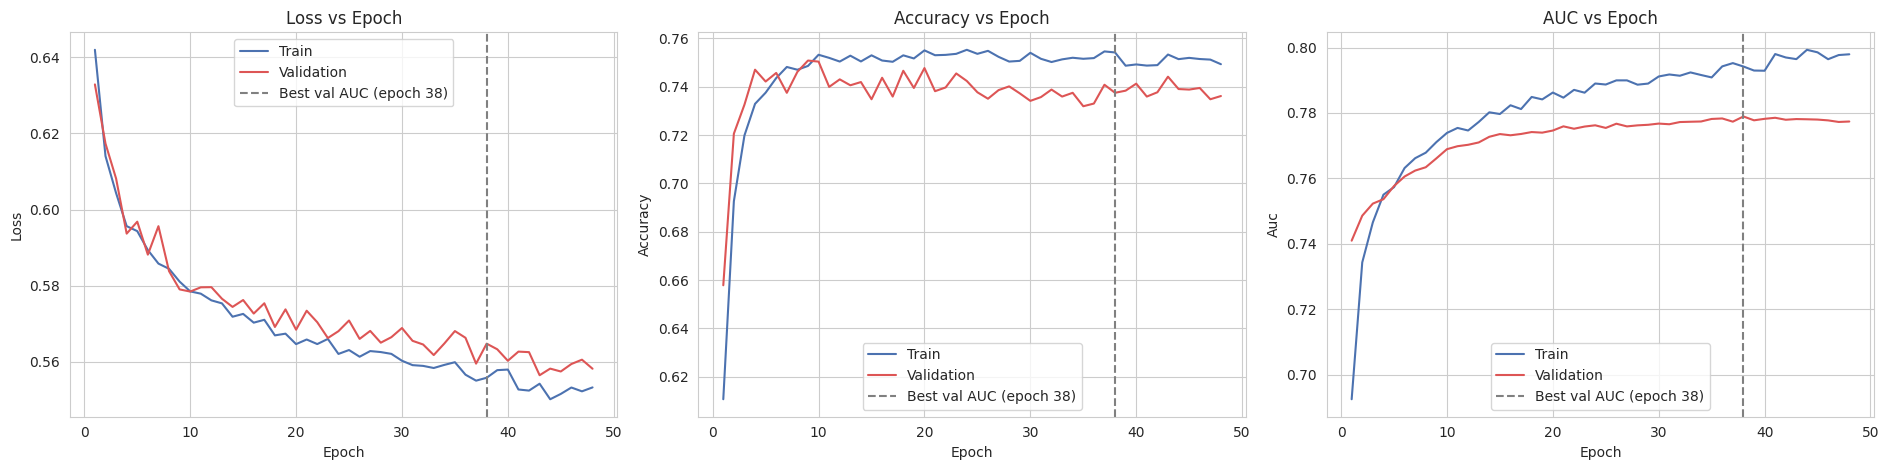

Best epoch by val AUC: 38 of 48


In [32]:
hist = pd.DataFrame(history.history)
best_ep = int(hist["val_auc"].idxmax()) + 1
ep = np.arange(1, len(hist) + 1)

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
for a, (tr, va, title) in zip(ax, [("loss", "val_loss", "Loss vs Epoch"),
                                   ("accuracy", "val_accuracy", "Accuracy vs Epoch"),
                                   ("auc", "val_auc", "AUC vs Epoch")]):
    a.plot(ep, hist[tr], label="Train", color="#4C72B0")
    a.plot(ep, hist[va], label="Validation", color="#DD5555")
    a.axvline(best_ep, color="grey", ls="--", label=f"Best val AUC (epoch {best_ep})")
    a.set_title(title); a.set_xlabel("Epoch"); a.set_ylabel(tr.capitalize()); a.legend()
save_fig("v13_training_curves")
print(f"Best epoch by val AUC: {best_ep} of {len(hist)}")

**Confusion matrix**

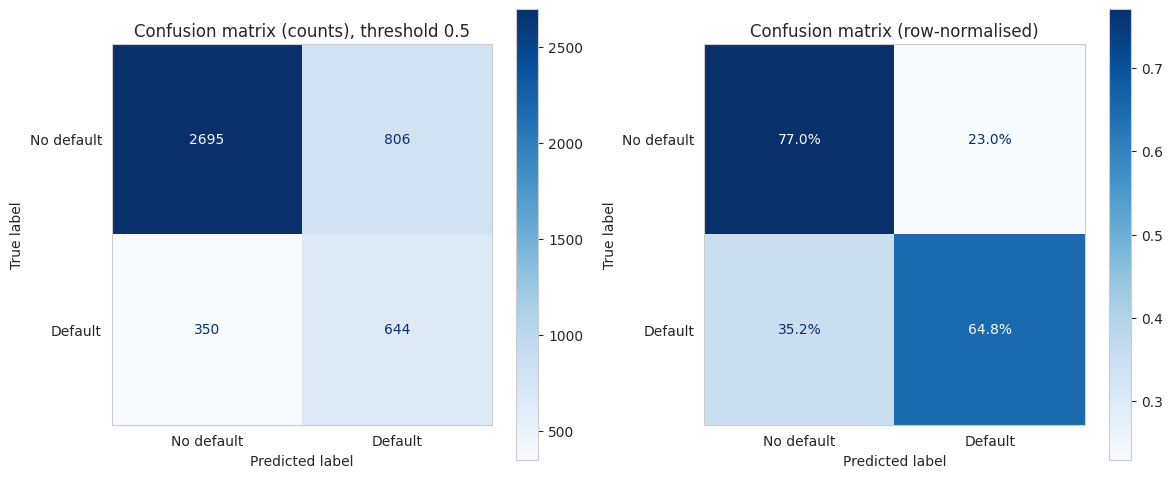

              precision    recall  f1-score   support

  No default      0.885     0.770     0.823      3501
     Default      0.444     0.648     0.527       994

    accuracy                          0.743      4495
   macro avg      0.665     0.709     0.675      4495
weighted avg      0.788     0.743     0.758      4495



In [33]:
y_pred_05 = (p_test >= 0.5).astype(int)
labels = ["No default", "Default"]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(yte, y_pred_05, display_labels=labels,
                                        cmap="Blues", values_format="d", ax=ax[0])
ax[0].set_title("Confusion matrix (counts), threshold 0.5"); ax[0].grid(False)
ConfusionMatrixDisplay.from_predictions(yte, y_pred_05, display_labels=labels,
                                        cmap="Blues", normalize="true",
                                        values_format=".1%", ax=ax[1])
ax[1].set_title("Confusion matrix (row-normalised)"); ax[1].grid(False)
save_fig("v14_confusion_matrix")

print(classification_report(yte, y_pred_05, target_names=labels, digits=3))

**ROC curves and AUC (MLP vs baselines)**

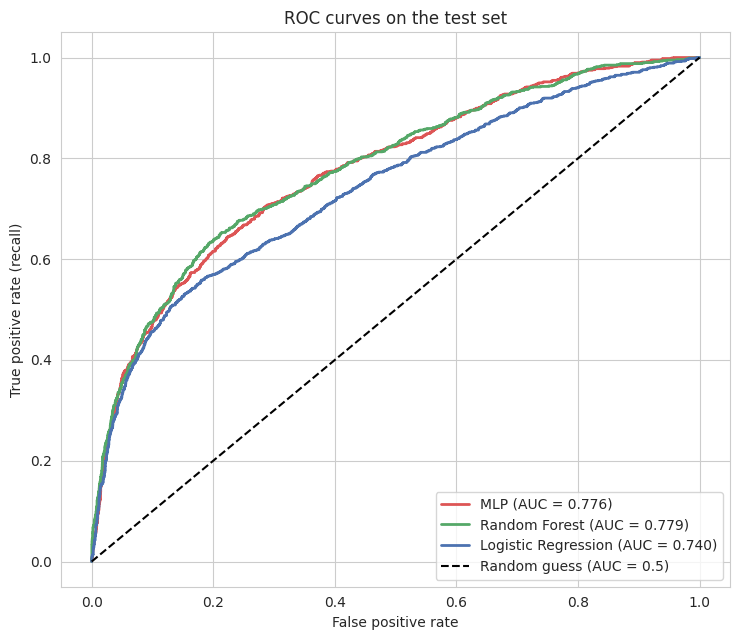

In [34]:
p_lr = lr.predict_proba(X_test_s)[:, 1]
p_rf = rf.predict_proba(X_test)[:, 1]       # the RF was trained on unscaled features

plt.figure(figsize=(7.5, 6.5))
for name, p, c in [("MLP", p_test, "#DD5555"), ("Random Forest", p_rf, "#55A868"),
                   ("Logistic Regression", p_lr, "#4C72B0")]:
    fpr, tpr, _ = roc_curve(yte, p)
    plt.plot(fpr, tpr, color=c, lw=2, label=f"{name} (AUC = {roc_auc_score(yte, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set"); plt.legend(loc="lower right")
save_fig("v15_roc_curves")

**Threshold analysis (threshold chosen on validation)**

Threshold chosen on validation set: 0.565


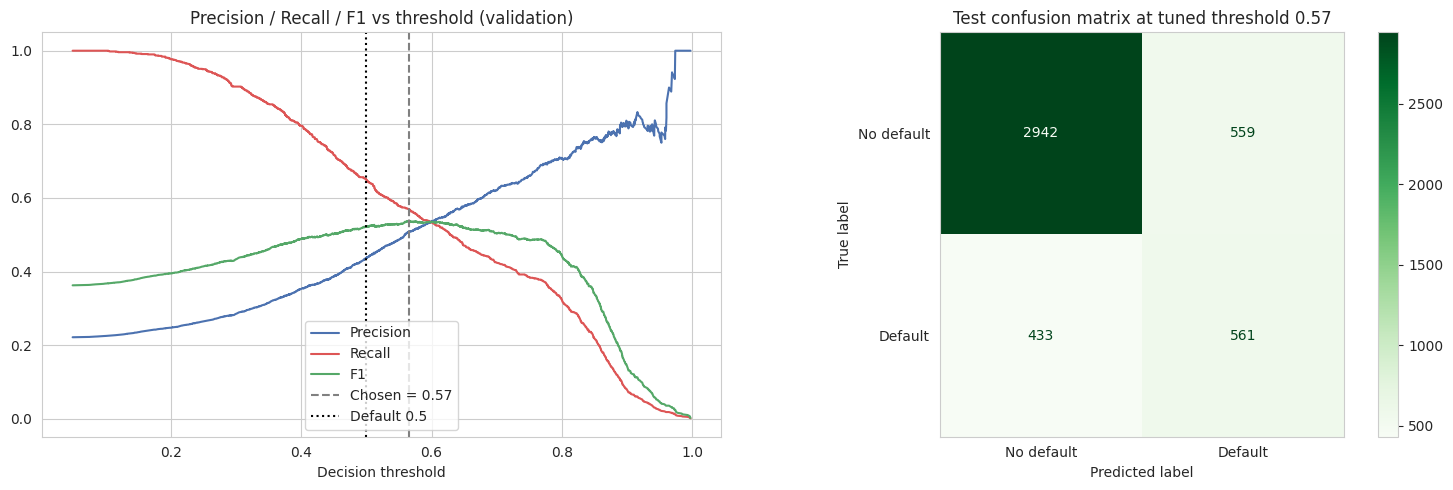

In [35]:
# Pick the F1-maximising threshold on the VALIDATION set only
prec, rec, thr = precision_recall_curve(yva, p_val)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = float(thr[np.argmax(f1[:-1])])
print(f"Threshold chosen on validation set: {best_thr:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(thr, prec[:-1], label="Precision", color="#4C72B0")
ax[0].plot(thr, rec[:-1],  label="Recall",    color="#DD5555")
ax[0].plot(thr, f1[:-1],   label="F1",        color="#55A868")
ax[0].axvline(best_thr, color="grey", ls="--", label=f"Chosen = {best_thr:.2f}")
ax[0].axvline(0.5, color="black", ls=":", label="Default 0.5")
ax[0].set_xlabel("Decision threshold"); ax[0].set_title("Precision / Recall / F1 vs threshold (validation)")
ax[0].legend()

y_pred_t = (p_test >= best_thr).astype(int)
ConfusionMatrixDisplay.from_predictions(yte, y_pred_t, display_labels=labels,
                                        cmap="Greens", values_format="d", ax=ax[1])
ax[1].set_title(f"Test confusion matrix at tuned threshold {best_thr:.2f}"); ax[1].grid(False)
save_fig("v16_threshold_analysis")

**Probability distributions and the final results table**

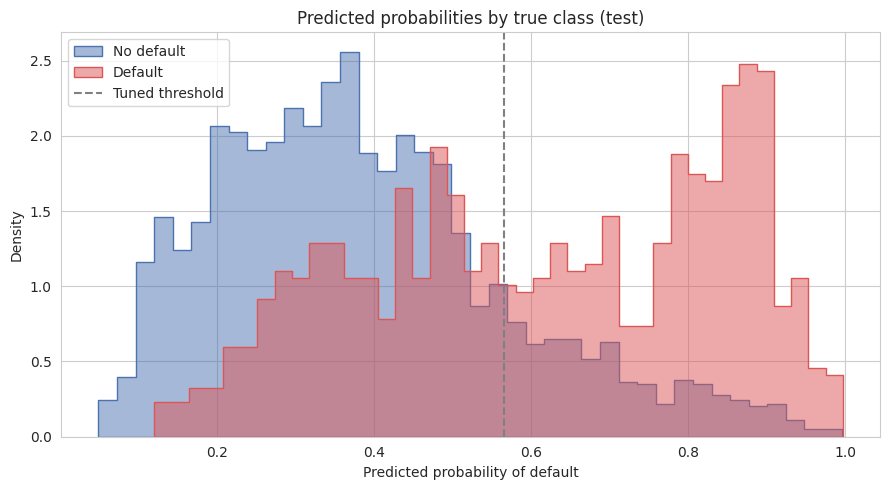

,Model,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
0,MLP (threshold 0.5),0.7428,0.4441,0.6479,0.5270,0.7760,0.5342
1,MLP (threshold 0.57),0.7793,0.5009,0.5644,0.5307,0.7760,0.5342
2,Logistic Regression,0.6774,0.3690,0.6459,0.4696,0.7396,0.5050
3,Random Forest,0.7778,0.4979,0.5996,0.5440,0.7793,0.5593


In [36]:
plt.figure(figsize=(9, 5))
for cls, name, c in [(0, "No default", "#4C72B0"), (1, "Default", "#DD5555")]:
    sns.histplot(p_test[yte == cls], bins=40, stat="density", alpha=0.5,
                 color=c, label=name, element="step")
plt.axvline(best_thr, color="grey", ls="--", label="Tuned threshold")
plt.xlabel("Predicted probability of default"); plt.title("Predicted probabilities by true class (test)")
plt.legend()
save_fig("v17_probability_distribution")

# Final comparison table for Section 8 of the report
def row(name, y_true, y_hat, p):
    return {"Model": name, "Accuracy": accuracy_score(y_true, y_hat),
            "Precision": precision_score(y_true, y_hat), "Recall": recall_score(y_true, y_hat),
            "F1": f1_score(y_true, y_hat), "ROC AUC": roc_auc_score(y_true, p),
            "PR AUC": average_precision_score(y_true, p)}

table = pd.DataFrame([
    row("MLP (threshold 0.5)", yte, y_pred_05, p_test),
    row(f"MLP (threshold {best_thr:.2f})", yte, y_pred_t, p_test),
    row("Logistic Regression", yte, (p_lr >= 0.5).astype(int), p_lr),
    row("Random Forest", yte, (p_rf >= 0.5).astype(int), p_rf),
]).round(4)
table.to_csv("data/test_results_table.csv", index=False)
table

**Download everything**

In [37]:
!zip -rq figures.zip figures
!zip -rq outputs.zip data model figures
from google.colab import files
files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Print every number you need in one place**

In [38]:
print("=== NUMBERS FOR YOUR REPORT ===")
print("Rows, columns (raw):", df.shape, "| model-ready:", df_model.shape)
print("Duplicates removed:", len(df) - len(df_clean))
print("Default rate: {:.2%}".format(df['default'].mean()))
print("Train/Val/Test:", X_train_s.shape[0], X_val_s.shape[0], X_test_s.shape[0])
print("Best config:", dict(best_cfg))
print("Epochs trained:", len(history.history['loss']), "| best epoch:", best_ep)
print(f"Val AUC {max(history.history['val_auc']):.4f} | Test AUC {test_auc:.4f} (CI {lo:.4f}-{hi:.4f})")
print("\nTop 5 permutation importance:\n", perm.head(5).round(4))
print("\nResults table:\n", table.to_string(index=False))

# Save dependencies for GitHub
import subprocess
open("requirements.txt", "w").write(
    subprocess.run("pip freeze | grep -iE '^(numpy|pandas|matplotlib|seaborn|scikit-learn|scipy|plotly|tensorflow|ucimlrepo)=='",
                   shell=True, capture_output=True, text=True).stdout)
print(open("requirements.txt").read())

=== NUMBERS FOR YOUR REPORT ===
Rows, columns (raw): (30000, 24) | model-ready: (29965, 31)
Duplicates removed: 35
Default rate: 22.12%
Train/Val/Test: 20975 4495 4495
Best config: {'units': '(64, 32)', 'dropout': np.float64(0.2), 'lr': np.float64(0.001), 'best_val_auc': np.float64(0.7789), 'epochs': np.int64(40), 'time_s': np.float64(53.1)}
Epochs trained: 48 | best epoch: 38
Val AUC 0.7789 | Test AUC 0.7760 (CI 0.7587-0.7920)

Top 5 permutation importance:
 PAY_1        0.0857
AVG_DELAY    0.0208
LIMIT_BAL    0.0115
BILL_AMT1    0.0105
BILL_AMT5    0.0087
dtype: float64

Results table:
                Model  Accuracy  Precision  Recall     F1  ROC AUC  PR AUC
 MLP (threshold 0.5)    0.7428     0.4441  0.6479 0.5270   0.7760  0.5342
MLP (threshold 0.57)    0.7793     0.5009  0.5644 0.5307   0.7760  0.5342
 Logistic Regression    0.6774     0.3690  0.6459 0.4696   0.7396  0.5050
       Random Forest    0.7778     0.4979  0.5996 0.5440   0.7793  0.5593
matplotlib==3.10.0
numpy==2.1.3
pa

**Print the remaining numbers**

In [41]:
print("--- Skewness / mean / median ---")
print(df_clean[cont4].agg(["mean", "median", "skew"]).T.round(2))
print("\n--- PAY_1: count and default rate ---")
print(df_clean.groupby("PAY_1")["default"].agg(["count", "mean"]).round(3))
print("\n--- Late-months (Binomial) ---")
print(f"mean={late.mean():.2f} var={late.var():.2f} binomial var={6*p_hat*(1-p_hat):.2f} p_hat={p_hat:.3f}")
print("\n--- PAY_AMT1 skew raw -> log1p ---")
print(round(raw.skew(), 2), "->", round(logged.skew(), 2))
print("\n--- Correlation with default ---")
print(corr["default"].drop("default").sort_values().round(2))
print("\n--- BILL_AMT inter-correlation (min) ---")
print(round(df_clean[bill_cols].corr().min().min(), 2))
print("\n--- Confusion matrices (test) ---")
print("thr 0.5 :\n", confusion_matrix(yte, y_pred_05))
print(f"thr {best_thr:.2f}:\n", confusion_matrix(yte, y_pred_t))
print("\nMLP params:", model.count_params())
print("\nTop MI:", list(mi.head(5).index), "\nTop RF:", list(rf_imp.head(5).index))
print("Val AUC  LR:", round(roc_auc_score(yva, lr.predict_proba(X_val_s)[:, 1]), 4),
      " RF:", round(roc_auc_score(yva, rf.predict_proba(X_val)[:, 1]), 4))
tune_df

--- Skewness / mean / median ---
                mean    median   skew
LIMIT_BAL  167442.01  140000.0   0.99
AGE            35.49      34.0   0.73
BILL_AMT1   51283.01   22438.0   2.66
PAY_AMT1     5670.10    2102.0  14.66

--- PAY_1: count and default rate ---
       count   mean
PAY_1              
-2      2750  0.132
-1      5682  0.168
 0     14737  0.128
 1      3667  0.340
 2      2666  0.691
 3       322  0.758
 4        76  0.684
 5        26  0.500
 6        11  0.545
 7         9  0.778
 8        19  0.579

--- Late-months (Binomial) ---
mean=0.83 var=2.42 binomial var=0.72 p_hat=0.139

--- PAY_AMT1 skew raw -> log1p ---
14.66 -> -1.3

--- Correlation with default ---
AVG_PAYMENT   -0.16
LIMIT_BAL     -0.15
PAY_AMT1      -0.14
PAY_AMT2      -0.14
PAY_AMT3      -0.12
PAY_AMT6      -0.11
PAY_AMT4      -0.11
PAY_AMT5      -0.11
BILL_AMT1     -0.03
BILL_AMT2     -0.02
BILL_AMT3     -0.02
AVG_BILL      -0.02
BILL_AMT4     -0.02
BILL_AMT5     -0.01
BILL_AMT6     -0.01
AGE          

,units,dropout,lr,best_val_auc,epochs,time_s
0,"(64, 32)",0.2,0.001,0.7789,40,53.1
1,"(64, 32)",0.2,0.003,0.7776,19,21.1
2,"(128, 64)",0.4,0.001,0.7773,27,17.6
3,"(128, 64)",0.2,0.001,0.7772,21,14.4
4,"(64, 32)",0.4,0.003,0.7771,23,12.7
5,"(64, 32)",0.4,0.001,0.7768,40,20.9
6,"(32, 16)",0.4,0.003,0.7761,32,15.2
7,"(128, 64)",0.4,0.003,0.7760,15,11.3
8,"(32, 16)",0.2,0.001,0.7756,40,41.6
9,"(32, 16)",0.2,0.003,0.7751,19,15.3
